# Exploring MaNGA Spectra and Data cubes


In this project, we're going to use small shifts in the observed wavelength of the Hydrogen H$\alpha$ gaseous emission line as a "tracer" of the velocity of gas orbiting inside a MaNGA galaxy (gas and stars tend to mix, so the gas velocities are likely similar to the stellar velocities).

**Goal of this notebook**: Generate an H$\alpha$ Velocity Field map of a disk galaxy

A "velocity field" is a 2D measure of line-of-sight velocity across the face of a galaxy.

## Ensure that you have a blue galaxy with H$\alpha$ emission

The code you produced in the HW-5 notebook, "Exploring MaNGA Galaxies," is our starting point here.

You will need to use that code to select a "blue" galaxy from the MaNGA sample.

As we learned in HW-5, blue galaxies show blue colors because they have young stars.  Young stars form from gas.  So it's good bet that your "blue" galaxy will have gas and therefore strong H$\alpha$ emission that we can use to trace the velocity field.

In this notebook, you will soon plot the H$\alpha$ spectral region in different parts of the galaxy.  If the H$\alpha$ emission looks pretty weak, you may need to choose a different blue galaxy.  You may even need to adjust  the way you selected blue galaxies in your HW-5 selection code.  Generally, a galaxy with $u-r$ color less than 1.7 should work.

In [2]:
# Cell for importing and setup preliminaries
from astropy.io import fits  # You'll need this to load MaNGA data cubes

# Also import your galaxy selection code from HW-5 "Exploring MaNGA Galaxies"

In [1]:
# Cell for running your selection code
# Choose a single "blue" galaxy to work with for the rest of this notebook

## Access the MaNGA data for your galaxy

The easiest way to uniquely identify your MaNGA galaxy is with its "plateifu" number, a combination of two numbers with a hyphen in between.  Such as '8138-9101'.

To get the data (and more info about your galaxy), we will use Marvin.  Marvin is a powerful interface to the MaNGA galaxy data that we built primarily in python.  Marvin includes a whole package of python tools for accessing MaNGA data, but for our purposes we will use [Marvin's web-based interface](https://dr17.sdss.org/marvin/).

At the top of the Marvin website, you'll see a field called "Plate or ID Designation."  Type in your plateifu number (with the hyphen) and a website should load with specific information about your galaxy.

For now, let's ignore the buttons that say things like "Use the spectrum in python" because those assume that we have the Marvin python tools loaded (you're welcome to explore that on your own, if you like).

Instead, click on the "Download" drop-down button and select "Cube".

This should download the (~150 MB) spectral data cube for this galaxy to your local disk.  It may take a few minutes and will have a filename like:
`manga-8138-9101-LOGCUBE.fits.gz`.


## Plot a spectrum at the center of your galaxy

The MaNGA spectra are organized in a format we call a **data cube**.  It's a three-dimensional array of flux measurements, $f$, providing the flux as a function of the $x,y$ position on the sky and the wavelength, $\lambda$.  That is, the data cube provides you with the function $f(x,y,\lambda)$.  There are a number of other things in the `LOGCUBE` files, but we'll be focusing on the flux data for the moment.

 - Open the file for your blue galaxy using `astropy.io.fits` and list its contents (see the aside on FITS files in the HW-5 notebook, "Exploring MaNGA Galaxies."  There should be 16 (yes, 16!) HDU file extensions.
 - The HDU extensions that we're mostly concerned with are:
  - `FLUX`: The extension with $f(x,y,\lambda)$
  - `IVAR`: The **inverse variance** in the flux measurements.  This holds the spectrum uncertainties.
  - `MASK`: A mask that indicates that a flux measurement should be ignored because the measurement was inaccurate for some reason.
  - `WAVE`: A vector with the list of wavelengths for each pixel in the $\lambda$ dimension.
 - Given the information provided by the `info()` member function, how many $x$, $y$ and $\lambda$ measurements are there in the datacube?

In [5]:
hdu_blue = fits.open('manga-8138-9101-LOGCUBE.fits.gz')
hdu_blue.info()

Filename: manga-8138-9101-LOGCUBE.fits.gz
No.    Name      Ver    Type      Cards   Dimensions   Format
  0  PRIMARY       1 PrimaryHDU      75   ()      
  1  FLUX          1 ImageHDU       100   (64, 64, 4563)   float32   
  2  IVAR          1 ImageHDU        17   (64, 64, 4563)   float32   
  3  MASK          1 ImageHDU        17   (64, 64, 4563)   int32   
  4  LSFPOST       1 ImageHDU        11   (64, 64, 4563)   float32   
  5  LSFPRE        1 ImageHDU        11   (64, 64, 4563)   float32   
  6  WAVE          1 ImageHDU         9   (4563,)   float64   
  7  SPECRES       1 ImageHDU         9   (4563,)   float64   
  8  SPECRESD      1 ImageHDU         9   (4563,)   float64   
  9  PRESPECRES    1 ImageHDU         9   (4563,)   float64   
 10  PRESPECRESD    1 ImageHDU         9   (4563,)   float64   
 11  OBSINFO       1 BinTableHDU    148   18R x 65C   [25A, 17A, 5A, J, I, 8A, E, E, E, E, E, E, J, J, I, J, E, 12A, J, 8A, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, E, 

An unfortunate annoyance is that astropy.io provides the data with an order that is transposed from what is shown using the `info()` member function.  So if you print the shape of the `FLUX` array, you should see the transpose of the dimensions provided by the `info()` function; i.e., the ordering of the flux measurements is $f(\lambda, y, x)$.

In [8]:
print(hdu_blue['FLUX'].data.shape)

# Notice that the array is easy to transpose:
print(hdu_blue['FLUX'].data.T.shape)

(4563, 64, 64)
(64, 64, 4563)


Given this, we're going to construct two arrays, one with the flux and another with the flux error, that are shaped according to $f(x,y,\lambda)$ and we will ignore any bad measurements in the array.  To do this, we're going to use a very convenient object that numpy provides called a [`MaskedArray`](https://docs.scipy.org/doc/numpy/reference/maskedarray.generic.html). 

In [12]:
wave_blue = hdu_blue['WAVE'].data
flux_blue = np.ma.MaskedArray(hdu_blue['FLUX'].data.T, mask=hdu_blue['MASK'].data.T > 0)
flux_blue_error = np.ma.power(np.ma.MaskedArray(hdu_blue['IVAR'].data.T,
                                                mask=hdu_blue['MASK'].data.T > 0),
                              -0.5)

The nice thing about `MaskedArray`s is that `matplotlib.pyplot` knows not to plot pixels that have been masked.  You can also do things like sum the flux measured at many wavelengths but automatically skip masked flux measurements.

#### Make the plot!

* Figure out which (x,y) position is the center of your data cube
* Plot the spectrum ("flux_blue" on the y-axis against wavelength on the x-axis)
* Don't forget axis labels

**Note**: You should use `step()` matplotlib function instead of the `plot()` function to plot a spectrum.  The version with `step()` shows the flux in each pixel more like a histogram instead of a smooth (or jagged as the case may be) connected line.  It gives you a better sense of how the data are collected.


In [15]:
# Cell: Central Spectrum
# In this cell, you will make a plot of the spectrum at the galaxy's center

## What is the spectrum telling me?

Galaxy spectra from MaNGA are generally composed of the following:

 - **Emission from stars**:  Stars provide most of the general shape of the spectrum, as well as a slew of narrow absorption features (sudden drops in flux) associated with discrete atomic and molecular energy-level transitions.
 - **Emission from ionized gas (plasma)**: Like a counterpart to the absorption features seen in stellar spectra, ionized gas will emit light at specific wavelengths associated with discrete atomic energy-level transitions.
 - **Dust**: Although there's no single thing to point to that shows the presence of dust, dust preferrentially scatters light at short wavelenths (look up **Rayleigh scattering**) such that the short wavelength end of the spectrum has less flux than it would have if we were looking at a "dust-free" galaxy.  Dust will not generally be important for our project, but it's good to keep in mind.
 - **Random noise**:  Our ability to measure the flux always has some theoretical and technical limitation.  MaNGA spectra are generally noisest at the shortest and largest wavelengths.
 

## Plot the spectrum in the outskirts of your galaxy

The relative contributions of *all* of these components will change as a function of position within the datacube.  That is, the spectrum you see at the center of the galaxy will generally be different than the spectrum you see at another position.  

You're going to plot the spectrum from a different location in your galaxy.  But first, let's plot a simple display of an _image_ (as opposed to the spectrum) of your galaxy, so that when you choose a different location, you have a sense of where in the galaxy you're looking.

### Display the reconstructed galaxy image

You can see a nice image of your galaxy from its Marvin webpage.  But, that image is separate from the MaNGA data.  It's not easy to see how your $(x,y)$ positions line up with that image.

Instead, you're going to plot a reconstructed image based on the MaNGA data itself.  The HDU extensions with `IMG` in the name are essentially integrals of the MaNGA spectra over a wavelength range corresponding to specified imaging filters.

Experiment with the commands in this cell to display an image of your galaxy...
* Try different filter bands like `RIMG` vs `GIMG`
* The default cell's code clips the image at a min=0 and a max=2.  What happens when you change this?
* Look out for bad pixels and notice the hexagonal footprint of where MaNGA data exists (i.e., some of the image is simply blank)
* Choose a final version that gives you a sense of the galaxy's orientation, shape, and ideally its structure, like spiral arms

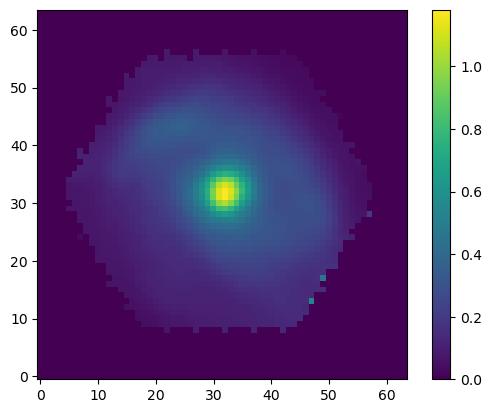

In [31]:
# Display a reconstrcted image of your galaxy
img = hdu_blue['GIMG'].data
plt.figure()
plt.imshow(np.clip(img,0,2), origin='lower', interpolation='nearest')
plt.colorbar()
plt.show()

### Overplot a spectrum at the ouskirts
* Using the image, find a valid $(x,y)$ position to represent the outskirts of the galaxy
* Remake your spectrum plot, but this time plot both central spectrum and a spectrum for the outskirts.
* Add a legend indicating which spectrum is which

In [15]:
# Cell: Central + Outskirts Spectrum
# In this cell, you will make a plot of the spectrum at the galaxy's center

### How to cheat with Marvin

If you haven't noticed already, Marvin web also displays an image that you can click on and see the spectrum at that location.  Toggle the red button "Map/SpecView" to "On'...  Do your plots match what Marvin shows?

## Zoom in on the H$\alpha$ Region

Notice that the emission features near 7000 angstroms have relatively more flux than the baseline flux, especially in the outskirts. These are a series of emission lines from nitrogen, hydrogen, and sulfur. Let's zoom in on them:

* Choose a wavelength range about 500 Angstroms wide that captures these lines
* Remake your plot choosing the better spectrum (outskirts?) and plotting just this spectral range

In [44]:
# Cell for H-alpha region zoom-in

## Emission lines (near H$\alpha$) 
The rest wavelengths of these lines (in vacuum) are given in the following table.

| Notation  | Element  | Rest wavelength |
|:---------:|:---------|:---------------:|
| [NII]     | Nitrogen | 6549.86         |
| H$\alpha$ | Hydrogen | 6564.632        |
| [NII]     | Nitrogen | 6585.271        |
| [SII]     | Sulfer   | 6718.294        |
| [SII]     | Sulfer   | 6732.674        |

The brackets, [], indicate that these are **forbidden transitions**, an interesting terminology for something we see all the time in astrophysics.    The "II" in, e.g., NII means that the transition is from *singly*-ionized nitrogen; i.e., a nitrogen atom that has ejected one of its electrons.  You'll see this written as N$^+$ in other fields, like physics and chemistry.  

The H$\alpha$ transition has a special notation that is historical.  It is the $\alpha$ transition in the **Balmer series** of transitions for singly-ionized hydrogen (i.e., HII or H$^+$).  Not all transitions in the optical are from singly-ionized species (there are transitions from doubly-ionized oxygen, OIII, and neutral nitrogen, NI), it just happens that all five of these emission lines are from singly-ionized species.

## Redshift

Notice that the lines don't land at the wavelengths listed above; this is because the entire spectrum experiences a **redshift** and **Doppler shift**.  We define the **redshift**, $z$, as follows:

$$1 + z = \frac{\lambda_{\rm obs}}{\lambda_{\rm rest}}$$

In your astro classes, you will learn about the differences between a redshift and Doppler shift, but for our purposes, let's think of this wavelength shift as arising from the relative motion between us and each part of the galaxy MaNGA observed.

The bulk of the wavelength shift in MaNGA data comes from the overall motion of the entire galaxy _away_ from us (as a result of [cosmic expansion](https://en.wikipedia.org/wiki/Hubble%27s_law)). Every MaNGA galaxy is far enough away from us that the effect of that intervening, expanding space makes all of them appear to recede from us.  In MaNGA the typical redshift is $z \sim 0.05$.

**BUT** after dividing out the overall galaxy redshift, any remaining wavelength shifts we observe across the galaxy must result from the relative motion of material in the galaxy.  This relative motion is what we're after in capturing the rotation curve.  We can approximate the relationship between wavelength shift and velocity as follows:

$$ z = \frac{\lambda_{\rm obs} - \lambda_{\rm rest}}{\lambda_{\rm rest}} \approx \frac{v_{\parallel}}{c}, $$

where $v_{\parallel}$ is the line-of-sight velocity and $c$ is the speed of light.

## Rotating galaxy disks in projection

Blue galaxies are mostly rotating, disk galaxies, and while these disks are intrinsically circular, their orientation in space is basically random.  As a result, we see these disks projected on the sky sometimes as circular ("face-on") and sometimes as fuzzy, bulgy lines ("edge-on"), and mostly as an elliptical shape that is something in between.

To observed a rotation curve, we can't have the disk galaxy be perfectly face-on.  In that case, all the motion of stars and gas rotating in the disk will be perpendicular to our line-of-sight.  We will observe no Doppler effect.

But, if the disk is at all tilted towards us, we will be able to measure wavelength shifts at many locations.  

### Overplot 3-5 spectra to highlight velocity-induced wavelength shifts

Think about this geometry and, with the reconstructed image as your guide, choose 3-5 pixels from the data cube that form a line running from one edge of the galaxy to the other.  Choose these locations in order to sample the _maximum_ deviation in rotating velocities that can be observed.

Overplot a further zoomed-in spectral region around the [NII] and H$\alpha$ lines from these different points below.  Do you see the spectral shifts?

In [50]:
# Plot of 3-5 points along a line in the galaxy, maximizing the shift in velocities

## Map an approximate velocity field

The last piece of the puzzle is to measure the wavelength shift of the peak of the $H\alpha$ line at every $(x,y)$ position in the data.  Once we have that, we can calculate the projected velocity field.

This last bit of code should be written in a standalone python file, because that way you will be able to use it for multiple galaxies.  

You should code up a function or set of functions that take the `plateifu`, the datacube file, and the DRPall file as inputs and returns your estimate of the velocity map.

As you build this code, please try out snippets of it by completing the instructions and cells below.

### Make an H$\alpha$ wavelength offset map

**Our Approximation** We're going to approximate the peak H$\alpha$ wavelength as that wavelength associated with the maximum (the peak) of a tiny portion of the spectrum enclosing the H$\alpha$ line.  In fact, it is possible to measure the peak wavelength location with better precision.  By considering the full extent of the line, we can actually measure the peak location with sub-pixel accuracy, but for now, we accept being limited by the coarse grain pixel width in wavelength.

* Before measuring H$\alpha$ wavelength offsets, you need to divide your wavelengths by $(1+z)$ (i.e., one plus the redshift) so that you can convert the observed wavelengths to _restframe_ wavelengths.
* Your code should look up your galaxy's redshift by referencing the DRPall catalog file.  The best redshift to use from that catalog is `NSA_Z`. (You worked with the DRPall file in HW-5 "Exploring MaNGA Galaxies").

Across the entire cube, your code needs to find the wavelength location of the maximum spectral value in a narrow wavelength window around the H$\alpha$ line.  

Use the plot above of 3-5 positions along the galaxy to make sure your wavelength window is defined so that it captures H$\alpha$.  To generalize this for any galaxy (at any redshift), you could start by working with restframe wavelengths.  The wavelength window should be something like 20 angstroms.

* You can write loops to record the max H$\alpha$ peak location, but there is a way to do it in one line with `np.argmax()`...!
* Once you have a 2D array (a map) of the $H\alpha$ peak wavelengths, subtract the peak wavelength value from the center of the galaxy.  After all, we're interested in how H$\alpha$ is moving _around_ the galaxy.  With this subtraction, you should have a wavelength offset map that will be positive and negative.

In [91]:
# Cells for making the H-alpha wavelength offset map (units are angstroms)

In [92]:
# Cell for plotting the offset map in this notebook
# Use plt.imshow() with plt.colorbar() and add some labels of units!
# You probably don't want to automatically plot in the stand-alone version of this code...

Notice that your map is discrete.  We only see the discrete wavelength values associated with each pixel in the `wave` array (the so-called "wavelength solution").

### Make and plot your approximate velocity field

You're close now!

* Convert the wavelength offset map to a velocity field map 
* You will need to refer back to the definitions of redshift and Doppler shift above
* You'll need to know the restframe wavelength of H$\alpha$ 
* You will need the speed-of-light in units of km/s (try `astropy.constants.c.to('km/s').value`)

In [ ]:
# Cells for making the velocity field

In [ ]:
# Cells for plotting the velocity field
# Use plt.imshow(..., cmap='RdBu_r')  That red-blue color map is standard for velocity fields.  
# Red colors are receding velocities (defined as positive values), 
# blue colors are approaching velocities (defined as negative values)

## Check your velocity field with Marvin

You have plotted a coarse-grain sampling of the 2D velocity field of your galaxy.  Wow.  A distant galaxy from half a billion years ago and you have now figured out how fast the gas in that galaxy is orbiting around (at least in projection).  A speed of 100 km/s means from Santa Cruz to San Francisco in about 1 second.  Not bad.   

Let's check your result against the velocity map from Marvin.

If you look at the Marvin page for your galaxy, by default one of the maps at the bottom is the stellar velocity map.  This one already gives you a clue and usually looks pretty similar to the gas or H$\alpha$ velocity map.  

But if you want to be specific, next to "DAP Maps" click on the button that says "3 items selected" and you'll get a dropdown of available maps.  Type "emline gvel Ha 6564" and select it.  Finally, click on the button that says "Get Maps" and a new map of H$\alpha$ velocity field, according to MaNGA's Data Analysis Pipeline, will appear.

How does your map compare to the version on Marvin???